STUDENT PERFORMANCE DATA ANALYSIS
Original rows: 202
Original columns: 6

--- Dataset preview ---
   student_id  gender  study_hours  attendance  previous_score  final_score
0        1001  Female          3.0       100.0            72.0         63.5
1        1002    Male          8.0        89.0            82.0         82.7
2        1003    Male          4.0        66.0            80.0         62.9
3        1004  Female          NaN        99.0            43.0         45.1
4        1005  Female          4.0        75.0            85.0         46.1

--- Data types ---
student_id          int64
gender             object
study_hours       float64
attendance        float64
previous_score    float64
final_score       float64
dtype: object

--- Missing values per column ---
student_id        0
gender            0
study_hours       3
attendance        2
previous_score    0
final_score       2
dtype: int64

--- Duplicate rows ---
2

--- Descriptive statistics ---
       student_id  study_hours

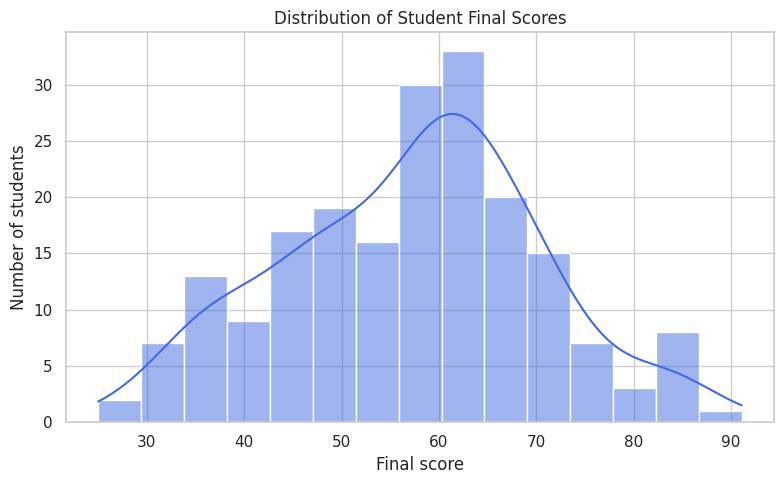

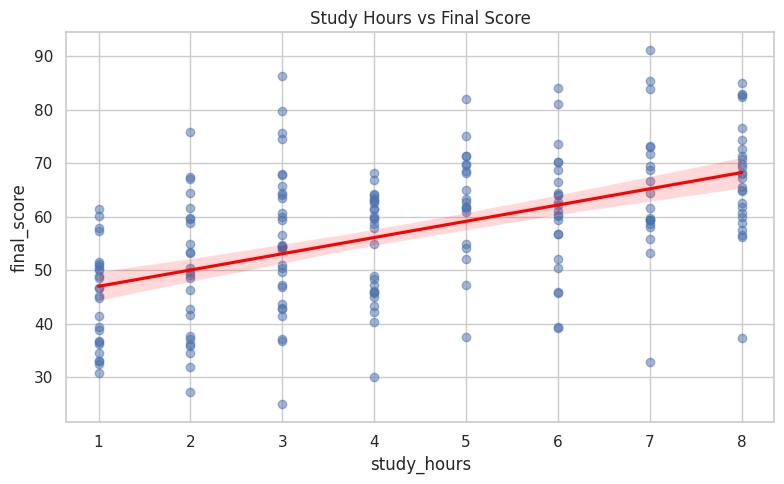

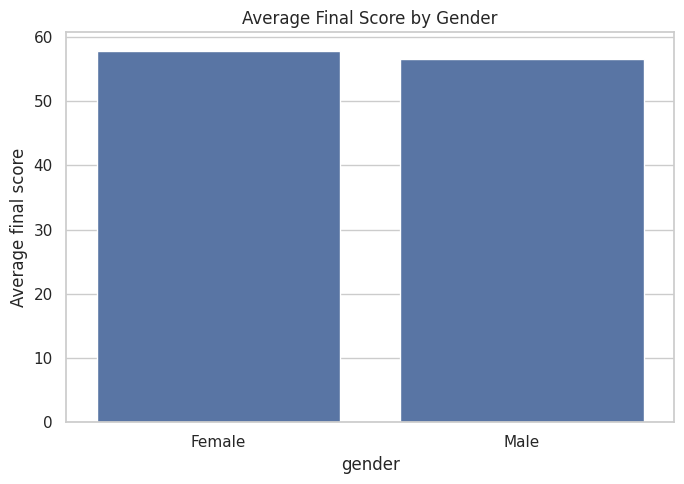

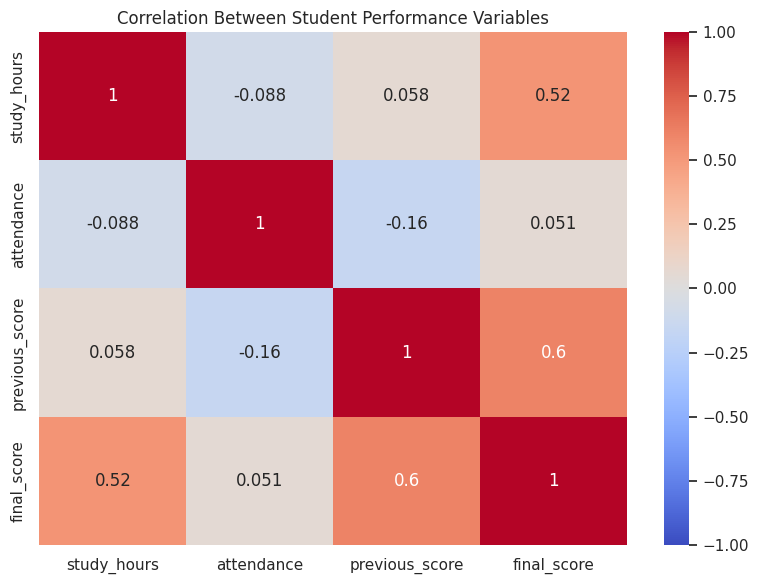


STUDENT PERFORMANCE: DATA QUALITY AND EDA REPORT

Project objective:
Inspect, clean and explore student performance data.

IMPORTANT:
The dataset is synthetic and created for educational purposes.
It does not represent real students.

DATA QUALITY FINDINGS
---------------------
Original number of rows: 202
Rows after duplicate removal: 200
Duplicate rows removed: 2

Missing values were checked in every column.
Impossible attendance and score values were treated as missing.
Missing numeric values were filled using column medians.

EXPLORATORY FINDINGS
--------------------
Average final score: 57.21
Median final score: 59.30
Minimum final score: 25.00
Maximum final score: 91.10
Average study hours: 4.36
Average attendance: 75.14

Variable with the strongest positive correlation with final score:
previous_score (correlation: 0.604)

Correlation does not prove causation. These results describe
the generated sample only and should not be generalized to real students.

CONCLUSION
----------

In [3]:
# STUDENT PERFORMANCE DATA QUALITY AND EDA
# EdVyro Milestone 2
# Note: This project uses synthetic sample data.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create an output folder
OUTPUT = Path("project_outputs")
OUTPUT.mkdir(exist_ok=True)

# 1. Generate a reproducible sample dataset
rng = np.random.default_rng(42)
n = 200

df = pd.DataFrame({
    "student_id": range(1001, 1001 + n),
    "gender": rng.choice(["Female", "Male"], n),
    "study_hours": rng.integers(1, 9, n).astype(float),
    "attendance": rng.integers(50, 101, n).astype(float),
    "previous_score": rng.integers(35, 96, n).astype(float)
})

noise = rng.normal(0, 8, n)
df["final_score"] = np.clip(
    0.45 * df["previous_score"]
    + 3.2 * df["study_hours"]
    + 0.18 * df["attendance"]
    + noise,
    0, 100
).round(1)

# Introduce issues to demonstrate data-quality checks
df.loc[[3, 15, 27], "study_hours"] = np.nan
df.loc[[8, 32], "attendance"] = np.nan
df.loc[[12, 44], "final_score"] = np.nan
df.loc[20, "attendance"] = 150       # Invalid attendance
df.loc[25, "final_score"] = -10      # Invalid score
df = pd.concat([df, df.iloc[[5, 10]]], ignore_index=True)

# Save original data
df.to_csv(OUTPUT / "student_data_raw.csv", index=False)

print("STUDENT PERFORMANCE DATA ANALYSIS")
print("=" * 45)
print(f"Original rows: {len(df)}")
print(f"Original columns: {len(df.columns)}")

# 2. Inspect the data
print("\n--- Dataset preview ---")
print(df.head())

print("\n--- Data types ---")
print(df.dtypes)

print("\n--- Missing values per column ---")
print(df.isnull().sum())

print("\n--- Duplicate rows ---")
print(df.duplicated().sum())

print("\n--- Descriptive statistics ---")
print(df.describe().round(2))

# 3. Clean the data
clean = df.drop_duplicates().copy()

# Replace impossible values with missing values
clean.loc[~clean["attendance"].between(0, 100), "attendance"] = np.nan
clean.loc[~clean["previous_score"].between(0, 100), "previous_score"] = np.nan
clean.loc[~clean["final_score"].between(0, 100), "final_score"] = np.nan
clean.loc[~clean["study_hours"].between(0, 24), "study_hours"] = np.nan

# Fill missing numeric values with their column medians
numeric_cols = [
    "study_hours", "attendance", "previous_score", "final_score"
]

for col in numeric_cols:
    clean[col] = clean[col].fillna(clean[col].median())

# Save cleaned data
clean.to_csv(OUTPUT / "student_data_cleaned.csv", index=False)

print("\n--- Cleaning summary ---")
print(f"Rows before cleaning: {len(df)}")
print(f"Rows after removing duplicates: {len(clean)}")
print(f"Duplicates removed: {len(df) - len(clean)}")
print("\nMissing values after cleaning:")
print(clean.isnull().sum())

# 4. Explore the cleaned data
print("\n--- Updated statistics ---")
print(clean[numeric_cols].describe().round(2))

print("\n--- Average final score by gender ---")
print(clean.groupby("gender")["final_score"].mean().round(2))

print("\n--- Average final score by study hours ---")
print(
    clean.groupby("study_hours")["final_score"]
    .mean().round(2)
)

correlation = clean[numeric_cols].corr()
print("\n--- Correlation matrix ---")
print(correlation.round(2))

# 5. Visualize the results
sns.set_theme(style="whitegrid")

# Chart 1: Final score distribution
plt.figure(figsize=(8, 5))
sns.histplot(clean["final_score"], bins=15, kde=True, color="royalblue")
plt.title("Distribution of Student Final Scores")
plt.xlabel("Final score")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig(OUTPUT / "score_distribution.png", dpi=150)
plt.show()

# Chart 2: Study hours and final score
plt.figure(figsize=(8, 5))
sns.regplot(
    data=clean, x="study_hours", y="final_score",
    scatter_kws={"alpha": 0.5}, line_kws={"color": "red"}
)
plt.title("Study Hours vs Final Score")
plt.tight_layout()
plt.savefig(OUTPUT / "study_vs_score.png", dpi=150)
plt.show()

# Chart 3: Average score by gender
plt.figure(figsize=(7, 5))
sns.barplot(data=clean, x="gender", y="final_score", errorbar=None)
plt.title("Average Final Score by Gender")
plt.ylabel("Average final score")
plt.tight_layout()
plt.savefig(OUTPUT / "score_by_gender.png", dpi=150)
plt.show()

# Chart 4: Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Student Performance Variables")
plt.tight_layout()
plt.savefig(OUTPUT / "correlation_heatmap.png", dpi=150)
plt.show()

# 6. Generate a simple project report
strongest = correlation["final_score"].drop("final_score").idxmax()
strongest_value = correlation.loc[strongest, "final_score"]

report = f"""
STUDENT PERFORMANCE: DATA QUALITY AND EDA REPORT
=================================================

Project objective:
Inspect, clean and explore student performance data.

IMPORTANT:
The dataset is synthetic and created for educational purposes.
It does not represent real students.

DATA QUALITY FINDINGS
---------------------
Original number of rows: {len(df)}
Rows after duplicate removal: {len(clean)}
Duplicate rows removed: {len(df) - len(clean)}

Missing values were checked in every column.
Impossible attendance and score values were treated as missing.
Missing numeric values were filled using column medians.

EXPLORATORY FINDINGS
--------------------
Average final score: {clean['final_score'].mean():.2f}
Median final score: {clean['final_score'].median():.2f}
Minimum final score: {clean['final_score'].min():.2f}
Maximum final score: {clean['final_score'].max():.2f}
Average study hours: {clean['study_hours'].mean():.2f}
Average attendance: {clean['attendance'].mean():.2f}

Variable with the strongest positive correlation with final score:
{strongest} (correlation: {strongest_value:.3f})

Correlation does not prove causation. These results describe
the generated sample only and should not be generalized to real students.

CONCLUSION
----------
The project demonstrates how duplicate records, missing values,
and invalid values can be detected and handled. Descriptive statistics
and charts help summarize the cleaned dataset and explore relationships.

FILES
-----
student_data_raw.csv
student_data_cleaned.csv
score_distribution.png
study_vs_score.png
score_by_gender.png
correlation_heatmap.png
"""

(OUTPUT / "analysis_report.txt").write_text(report, encoding="utf-8")
print(report)

print(f"\nAll project outputs are saved in: {OUTPUT.resolve()}")
print("Project analysis completed successfully.")